# Follow-up analysis: what stricter name matching reveals

`01_lighthr_audit.ipynb` builds its Russell Group flag by **exact** name matching. The dataset spells some universities several ways (`" University of Oxford"` with a leading space, `"Universirt of Cambridge"`, `"University of Nottingham, The"`, …), so normalising the names before matching finds **588 more Russell Group graduates**.

This notebook:

1. builds a normalised flag (`lighthr/universities.py`, with tests) and compares the two;
2. shows what the extra matches reveal: a **prestige bonus** in the labels, concentrated in four university spellings;
3. retrains the final AdaBoost model with the normalised flag, which makes it *more accurate and less fair*;
4. extends the fairness analysis with **more privileged/unprivileged definitions** and **deeper individual fairness** (per-group consistency, counterfactual flips for every protected attribute);
5. runs and compares two Russell Group mitigations (feature ablation and Reweighing on Russell Group).

Everything uses the same features, the same 80/20 stratified split and the same AdaBoost hyperparameters as `01_lighthr_audit.ipynb`.

In [1]:
import logging
import warnings
warnings.filterwarnings("ignore")
logging.disable(logging.WARNING)   # silence aif360's notices about optional extras

import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from aif360.algorithms.preprocessing import Reweighing
from aif360.datasets import BinaryLabelDataset
from sklearn.metrics import accuracy_score, f1_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

from lighthr.pipeline import fit_adaboost, prepare, split
from lighthr.universities import RUSSELL_GROUP, spelling_report

CSV_PATH = "../data/LightHR_dataset.csv"
FIG_DIR = "../docs/figures"

# Chart colours: categorical slots 1-3 of a colourblind-validated palette, plus a neutral.
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a85"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True, "font.size": 10,
})
pd.set_option("display.precision", 3)

## 1. Exact versus normalised matching

`spelling_report` lists every raw spelling that only matches a Russell Group university after normalisation.

In [2]:
raw_sub, cls_sub = prepare(CSV_PATH, russell_group="exact")
raw, cls = prepare(CSV_PATH, russell_group="normalised")

print(spelling_report(raw["University"]).to_string(index=False))

def raw_di(frame):
    rg = frame.loc[frame.Russell_Group == 1, "Hired"].mean()
    non = frame.loc[frame.Russell_Group == 0, "Hired"].mean()
    return rg, non, non / rg

summary = pd.DataFrame(
    [[(raw_sub.Russell_Group == 1).sum(), *raw_di(raw_sub)],
     [(raw.Russell_Group == 1).sum(), *raw_di(raw)]],
    index=["Exact matching", "Normalised matching"],
    columns=["Russell Group rows", "RG hire rate", "Non-RG hire rate", "Disparate impact"],
)
summary

                                      raw name  rows                                          matches
                          University of Oxford   160                             UNIVERSITY OF OXFORD
                       Universirt of Cambridge   146                          UNIVERSITY OF CAMBRIDGE
                  THE UNIVERSITY OF MANCHESTER    60                         UNIVERSITY OF MANCHESTER
                 UNIVERSITY OF NOTTINGHAM, THE    57                         UNIVERSITY OF NOTTINGHAM
                 QUEEN'S UNIVERSITY OF BELFAST    57                       QUEEN'S UNIVERSITY BELFAST
LONDON SCHOOL OF ECONOMICS & POLITICAL SCIENCE    57 LONDON SCHOOL OF ECONOMICS AND POLITICAL SCIENCE
                          UNIVERSITY OF DURHAM    51                                DURHAM UNIVERSITY


,Russell Group rows,RG hire rate,Non-RG hire rate,Disparate impact
Exact matching,1347,0.358,0.218,0.610
Normalised matching,1935,0.437,0.184,0.422


The normalised flag finds 1,935 Russell Group graduates instead of 1,347, and the raw disparate impact falls from **0.61 to 0.42**. Russell Group is the largest disparity under exact matching too; with normalised matching it is considerably larger.

## 2. What the extra matches reveal

Most of the labels follow two hard rules: every applicant with A-levels above 80 (all of whom are employed) is hired, and nobody with A-levels below 70 or without a job is hired. The only open band is **employed applicants with A-levels of 70–80**. Breaking that band down by university spelling:

In [3]:
PRESTIGE = [" University of Oxford", "Universirt of Cambridge",
            "University College London", "IMPERIAL COLLEGE LONDON"]

def spelling_group(frame):
    g = pd.Series("Non-Russell Group", index=frame.index)
    g[frame.Russell_Group == 1] = "Other Russell Group"
    g[frame.University.isin(PRESTIGE)] = "Four prestige spellings"
    return g

mid = raw.ALevels.between(70, 80) & (raw.Employment != "None")
by_uni = (raw[mid].groupby("University")["Hired"].agg(["mean", "size"])
          .rename(columns={"mean": "hire rate (A-levels 70-80, employed)", "size": "n"})
          .sort_values("hire rate (A-levels 70-80, employed)", ascending=False))
by_uni.head(8)

,"hire rate (A-levels 70-80, employed)",n
University,,
University of Oxford,1.000,38
University College London,1.000,41
Universirt of Cambridge,1.000,40
ROYAL CONSERVATOIRE OF SCOTLAND,0.857,7
IMPERIAL COLLEGE LONDON,0.850,40
LONDON SOUTH BANK UNIVERSITY,0.571,7
SOUTHAMPTON SOLENT UNIVERSITY,0.500,10
UNIVERSITY OF SURREY,0.500,8


In [4]:
# Same university, different spelling.
same_uni = raw[raw.University.str.upper().str.strip().str.contains(
    r"^UNIVERSI\w+ OF (?:OXFORD|CAMBRIDGE)$|^UNIVERSITY COLLEGE LONDON$")]
same_uni.groupby("University")["Hired"].agg(hire_rate="mean", rows="size")

,hire_rate,rows
University,,
University of Oxford,1.000,160
UNIVERSITY COLLEGE LONDON,0.192,52
UNIVERSITY OF CAMBRIDGE,0.125,56
UNIVERSITY OF OXFORD,0.231,65
Universirt of Cambridge,1.000,146
University College London,1.000,149


Four spellings stand out. Employed applicants with A-levels of 70–80 from these four are hired **85–100%** of the time, against about **20%** for everyone else in the same band. (The next spelling, at 86%, has only 7 applicants.)

The effect follows the *record*, not the university. `"University of Oxford"` spelled normally is hired at 23%; with a leading space, 100%. The same holds for Cambridge and for UCL in mixed case versus upper case. In a real dataset that would point at one recruiter, office or data source; in this synthetic one it looks like a deliberately planted bias. Either way, a model trained on these labels can learn it.

Exact matching already catches UCL and Imperial (spelled correctly, just in different case) but misses the Oxford and Cambridge variants, which is why the Russell Group effect looks smaller under exact matching.

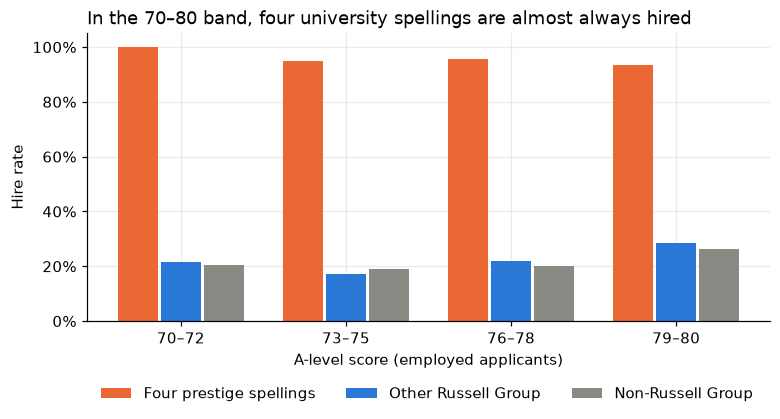

,Four prestige spellings,Other Russell Group,Non-Russell Group
70–72,1.000,0.214,0.204
73–75,0.947,0.173,0.191
76–78,0.956,0.220,0.201
79–80,0.933,0.286,0.262


In [5]:
bands = [(70, 72), (73, 75), (76, 78), (79, 80)]
band_label = [f"{a}–{b}" for a, b in bands]
grp = spelling_group(raw)
employed = raw.Employment != "None"
rates = pd.DataFrame({
    g: [raw.loc[employed & raw.ALevels.between(a, b) & (grp == g), "Hired"].mean() for a, b in bands]
    for g in ["Four prestige spellings", "Other Russell Group", "Non-Russell Group"]
}, index=band_label)

fig, ax = plt.subplots(figsize=(7.5, 4))
x = np.arange(len(bands)); w = 0.26
for i, (g, c) in enumerate(zip(rates.columns, [ORANGE, BLUE, GREY])):
    ax.bar(x + (i - 1) * w, rates[g], w - 0.02, color=c, label=g)
ax.set_xticks(x, band_label)
ax.set_xlabel("A-level score (employed applicants)")
ax.set_ylabel("Hire rate")
ax.set_ylim(0, 1.05)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("In the 70–80 band, four university spellings are almost always hired", loc="left")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, -0.18), ncol=3)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/followup_prestige_bonus.png", dpi=150, bbox_inches="tight")
plt.show()
rates

## 3. Retraining with the normalised flag

Same split, same AdaBoost (200 estimators, learning rate 1.0), only the `Russell_Group` column differs.

In [6]:
s_sub, s = split(cls_sub), split(cls)
assert s_sub.X_test.index.equals(s.X_test.index)   # identical rows in train and test

model_sub = fit_adaboost(s_sub.X_train, s_sub.y_train)
model = fit_adaboost(s.X_train, s.y_train)
pred_sub = model_sub.predict(s_sub.X_test)
pred = model.predict(s.X_test)

pd.DataFrame({
    "Test accuracy": [accuracy_score(s.y_test, pred_sub), accuracy_score(s.y_test, pred)],
    "Test F1 (hired)": [f1_score(s.y_test, pred_sub), f1_score(s.y_test, pred)],
}, index=["Exact-match flag", "Normalised flag"])

,Test accuracy,Test F1 (hired)
Exact-match flag,0.976,0.950
Normalised flag,0.980,0.958


The model with the normalised flag is **more accurate** (0.976 → 0.980): it can now see the Russell Group status of the prestige records and learns that it predicts hiring. The question is what it does with that.

In [7]:
test = raw.loc[s.X_test.index].assign(pred_sub=pred_sub, pred=pred, group=spelling_group(raw.loc[s.X_test.index]))
mid_t = test.ALevels.between(70, 80) & (test.Employment != "None")
amp = test[mid_t].groupby("group").agg(
    n=("Hired", "size"), actual=("Hired", "mean"),
    predicted_exact=("pred_sub", "mean"), predicted_normalised=("pred", "mean"),
).loc[["Four prestige spellings", "Other Russell Group", "Non-Russell Group"]]
amp

,n,actual,predicted_exact,predicted_normalised
group,,,,
Four prestige spellings,35,0.943,0.686,0.943
Other Russell Group,35,0.143,0.400,0.486
Non-Russell Group,222,0.212,0.185,0.135


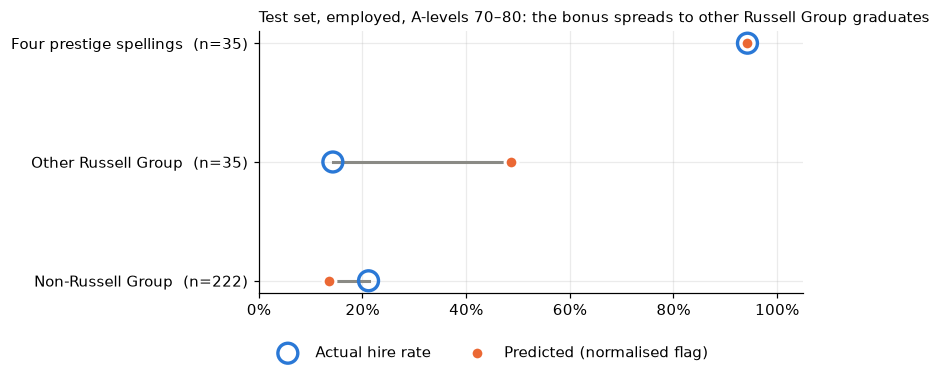

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
order = amp.index.tolist()
y = np.arange(len(order))
for yi, g in zip(y, order):
    a, p = amp.loc[g, "actual"], amp.loc[g, "predicted_normalised"]
    ax.plot([a, p], [yi, yi], color=GREY, lw=2, zorder=1)
ax.scatter(amp["actual"], y, s=170, facecolor="none", edgecolor=BLUE, linewidth=2.2, label="Actual hire rate", zorder=4)
ax.scatter(amp["predicted_normalised"], y, s=70, color=ORANGE, label="Predicted (normalised flag)", zorder=3, edgecolor="white", linewidth=2)
ax.set_yticks(y, [f"{g}  (n={amp.loc[g, 'n']})" for g in order])
ax.invert_yaxis()
ax.set_xlim(0, 1.05)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Test set, employed, A-levels 70–80: the bonus spreads to other Russell Group graduates", loc="left", fontsize=10)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, -0.15), ncol=2)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/followup_amplification.png", dpi=150, bbox_inches="tight")
plt.show()

This is the core finding. In the band where the decision is open, the model with the normalised flag:

* reproduces the prestige bonus for the four spellings (94% predicted, 94% actual);
* **extends it to the other Russell Group graduates**: it predicts 49% of them will be hired when only 14% were, because all it can see is the shared `Russell_Group = 1`;
* **pushes non-Russell Group applicants down**, to 14% predicted against 21% actual.

The exact-match model already does a milder version of this (40% predicted for other Russell Group graduates), because exact matching does catch two of the four prestige spellings, UCL and Imperial. The normalised flag makes the pattern stronger. The groups are small in this band (35 applicants each in the first two rows), so the exact percentages are noisy, but the direction is clear and it shows up again in the group metrics below.

So better matching does not just reveal a larger disparity. It gives the model a clean proxy for the planted bias, and the model amplifies it. The extra accuracy came from learning the bias.

## 4. Group fairness with the normalised flag

The metrics below are computed directly (selection rates and true-positive rates on the test set). The first check confirms they match the aif360 numbers in `01_lighthr_audit.ipynb`.

In [9]:
def group_metrics(frame, priv, unpriv, y="Hired", yhat="pred"):
    """Disparate impact, statistical parity and equal opportunity for two boolean masks."""
    sel = lambda m: frame.loc[m, yhat].mean()
    tpr = lambda m: frame.loc[m & (frame[y] == 1), yhat].mean()
    return {
        "n priv": int(priv.sum()), "n unpriv": int(unpriv.sum()),
        "GT DI": frame.loc[unpriv, y].mean() / frame.loc[priv, y].mean(),
        "Model DI": sel(unpriv) / sel(priv),
        "SPD": sel(unpriv) - sel(priv),
        "EOD": tpr(unpriv) - tpr(priv),
    }

sub_test = raw_sub.loc[s.X_test.index].assign(pred=pred_sub)
check = group_metrics(sub_test, sub_test.Russell_Group == 1, sub_test.Russell_Group == 0)
assert round(check["Model DI"], 3) == 0.630 and round(check["SPD"], 3) == -0.127   # matches 01_lighthr_audit.ipynb
check

{'n priv': 283,
 'n unpriv': 1477,
 'GT DI': 0.6685777668937899,
 'Model DI': 0.6301223572440653,
 'SPD': -0.12677784928383626,
 'EOD': 0.022638816813700058}

In [10]:
rg_table = pd.DataFrame({
    "Exact-match flag": group_metrics(sub_test, sub_test.Russell_Group == 1, sub_test.Russell_Group == 0),
    "Normalised flag": group_metrics(test, test.Russell_Group == 1, test.Russell_Group == 0),
}).T
rg_table

,n priv,n unpriv,GT DI,Model DI,SPD,EOD
Exact-match flag,283.0,1477.0,0.669,0.630,-0.127,0.023
Normalised flag,400.0,1360.0,0.482,0.419,-0.250,-0.066


With the normalised flag the model's Russell Group disparate impact is far below the 0.80 benchmark, below the exact-match 0.630 and below the ground truth: the model is adding bias on top of the labels.

In [11]:
inter = test.groupby(["Gender", "Russell_Group"]).agg(n=("Hired", "size"), actual=("Hired", "mean"), predicted=("pred", "mean"))
inter

n  actual  predicted
Gender     Russell_Group                        
Female     0              322   0.177      0.158
           1               81   0.469      0.494
Male       0              276   0.243      0.228
           1               99   0.455      0.465
Non-binary 0              375   0.147      0.139
           1              110   0.391      0.455
Trans      0              387   0.214      0.204
           1              110   0.309      0.327

## 5. More privileged/unprivileged definitions

`01_lighthr_audit.ipynb` compares gender pairs, age 45+ vs under 45, Russell Group, and pre-COVID vs COVID (where "pre-COVID" also includes 2022, i.e. *post*-COVID applicants). Below, every split is defined explicitly, and splits are tagged by whether the attribute is a protected characteristic under the Equality Act 2010 or is job-relevant. Disparate impact on a job-relevant attribute is expected, which is exactly why DI alone is not a verdict.

In [12]:
t = test
covid = t.Year.between(2020, 2021)
splits = [
    # (name, privileged mask, unprivileged mask, kind)
    ("Gender: Male vs all others",        t.Gender == "Male",       t.Gender != "Male",       "Protected (sex / gender reassignment)"),
    ("Gender: Female vs all others",      t.Gender == "Female",     t.Gender != "Female",     "Protected (sex / gender reassignment)"),
    ("Gender: Non-binary vs all others",  t.Gender != "Non-binary", t.Gender == "Non-binary", "Protected (sex / gender reassignment)"),
    ("Gender: Trans vs all others",       t.Gender != "Trans",      t.Gender == "Trans",      "Protected (sex / gender reassignment)"),
    ("Age: 40-44 vs 45-49",               t.Age < 45,               t.Age >= 45,              "Protected (age)"),
    ("Age: 40-42 vs 47-49 (extremes)",    t.Age <= 42,              t.Age >= 47,              "Protected (age)"),
    ("Year: 2008-19 vs 2020-21 (COVID)",  t.Year.between(2008, 2019), covid,                  "Context (graduation cohort)"),
    ("Year: 2022 vs 2020-21 (COVID)",     t.Year == 2022,           covid,                    "Context (graduation cohort)"),
    ("Year: 1998-2007 vs 2008-19",        t.Year.between(2008, 2019), t.Year <= 2007,         "Protected proxy (age)"),
    ("University: Russell Group vs not",  t.Russell_Group == 1,     t.Russell_Group == 0,     "Proxy (socio-economic)"),
    ("University: prestige-4 vs other RG", t.group == "Four prestige spellings", t.group == "Other Russell Group", "Proxy (socio-economic)"),
    ("Education: Arts vs STEM",           t.Education == "Arts",    t.Education == "STEM",    "Context (degree subject)"),
    ("Employment: employed vs not",       t.Employment != "None",   t.Employment == "None",   "Job-relevant"),
    ("References: given vs none",       t.RefsSubmitted == 1,     t.RefsSubmitted == 0,     "Job-relevant"),
]
wide = pd.DataFrame({name: {**group_metrics(t, p, u), "kind": kind} for name, p, u, kind in splits}).T
wide[["kind", "n priv", "n unpriv", "GT DI", "Model DI", "SPD", "EOD"]]

,kind,n priv,n unpriv,GT DI,Model DI,SPD,EOD
Gender: Male vs all others,Protected (sex / gender reassignment),375,1385,0.749,0.765,-0.068,-0.004
Gender: Female vs all others,Protected (sex / gender reassignment),403,1357,1.022,1.064,0.014,0.02
Gender: Non-binary vs all others,Protected (sex / gender reassignment),1275,485,0.795,0.851,-0.037,0.022
Gender: Trans vs all others,Protected (sex / gender reassignment),1263,497,0.975,0.968,-0.008,-0.005
Age: 40-44 vs 45-49,Protected (age),876,884,0.963,0.949,-0.012,0.008
Age: 40-42 vs 47-49 (extremes),Protected (age),520,536,1.037,1.073,0.016,0.044
Year: 2008-19 vs 2020-21 (COVID),Context (graduation cohort),826,137,0.739,0.68,-0.079,-0.091
Year: 2022 vs 2020-21 (COVID),Context (graduation cohort),75,137,0.684,0.63,-0.099,-0.12
Year: 1998-2007 vs 2008-19,Protected proxy (age),826,722,0.97,0.953,-0.012,-0.034
University: Russell Group vs not,Proxy (socio-economic),400,1360,0.482,0.419,-0.25,-0.066


What the wider set adds:

* **One-vs-rest gender splits** give one number per group instead of six pairwise ones. The split that fails the 0.80 benchmark is **Male vs everyone else** (0.765): the disadvantage is shared by all three other groups rather than belonging to one. Non-binary vs everyone else passes (0.851), and the model is slightly fairer than the labels (0.795).
* **Age** shows no disadvantage at either cut (0.95 and 1.07), consistent with the 45+ split in `01_lighthr_audit.ipynb`.
* Separating **2022** from the pre-COVID cohort matters. The COVID-era cohort (2020–21) is disadvantaged against 2008–19 (0.68) *and* against 2022 (0.63), so lumping 2022 into "pre-COVID" understated the COVID effect. These cohorts are small (137 and 75 test applicants).
* **Employment** and **references** have disparate impact of exactly 0, because nobody without a job or without references is hired. These splits show that a DI below 0.8 is a prompt to justify the attribute, not proof of unfairness: requiring references can be defended, requiring a Russell Group degree is much harder to.
* Within the Russell Group, **prestige-4 vs other RG** has a DI of 0.20: most of the "Russell Group" disparity comes from 665 records.

## 6. Deeper individual fairness

### 6a. Consistency by group

Consistency asks whether similar applicants get similar predictions: for each applicant, compare the prediction with the predictions of its *k* = 5 nearest neighbours in a feature space with the protected attributes removed. `01_lighthr_audit.ipynb` gives one number for the whole test set (0.8835). Here it is broken down by group. Age and year of application are removed from the neighbour space as well as gender, and it is computed twice: with `Russell_Group` in the neighbour space (as in `01_lighthr_audit.ipynb`) and without it (treating it as the proxy it is).

In [13]:
X_test = s.X_test
protected = ["Gender", "Age", "Year"]

def consistency_by_point(X, yhat, drop, k=5):
    Z = StandardScaler().fit_transform(X.drop(columns=drop).to_numpy())
    _, idx = NearestNeighbors(n_neighbors=k + 1).fit(Z).kneighbors(Z)
    return 1 - np.abs(yhat - yhat[idx[:, 1:]].mean(axis=1))

c_with = consistency_by_point(X_test, pred, protected)
c_without = consistency_by_point(X_test, pred, protected + ["Russell_Group"])
# The score in 01_lighthr_audit.ipynb removes only Gender from the neighbour space (Age and Year stay in).
c_sub = consistency_by_point(s_sub.X_test, pred_sub, ["Gender"])
assert round(c_sub.mean(), 4) == 0.8835   # matches 01_lighthr_audit.ipynb

cons = pd.DataFrame({"group": test.Gender.values, "rg": np.where(test.Russell_Group == 1, "Russell Group", "Non-RG"),
                     "with RG": c_with, "without RG": c_without})
cons_table = pd.concat([
    cons.groupby("group")[["with RG", "without RG"]].mean(),
    cons.groupby("rg")[["with RG", "without RG"]].mean(),
    cons[["with RG", "without RG"]].mean().rename("All test applicants").to_frame().T,
])
cons_table

,with RG,without RG
Female,0.924,0.919
Male,0.905,0.900
Non-binary,0.910,0.909
Trans,0.890,0.904
Non-RG,0.910,0.917
Russell Group,0.892,0.878
All test applicants,0.906,0.908


Consistency is broadly similar across gender groups (Trans applicants lowest at 0.890). Removing `Russell_Group` from the neighbour space barely moves the overall score, but it splits by group: consistency **falls for Russell Group graduates** (0.892 → 0.878) and rises for everyone else. Once university is treated as irrelevant, a Russell Group graduate's nearest neighbours are equally qualified non-RG applicants who get a different prediction. That is the individual-level view of the proxy effect.

### 6b. Counterfactual flips for every protected attribute

`01_lighthr_audit.ipynb` flips gender and Russell Group. Here every protected attribute (and the Russell Group proxy) is changed one at a time, with the rest of the applicant fixed, and the table counts how many predictions change and in which direction.

In [14]:
gender_codes = dict(zip(sorted(raw.Gender.unique()), range(4)))   # LabelEncoder order

def flip(model, X, base, col, value, label):
    Xc = X.copy()
    Xc[col] = value(Xc[col]) if callable(value) else value
    new = model.predict(Xc)
    return {"change": label, "flip rate": (new != base).mean(),
            "gained hire": ((new == 1) & (base == 0)).mean(), "lost hire": ((new == 0) & (base == 1)).mean()}

cf = pd.DataFrame(
    [flip(model, X_test, pred, "Gender", code, f"Gender → {g}") for g, code in gender_codes.items()]
    + [flip(model, X_test, pred, "Age", 40, "Age → 40"), flip(model, X_test, pred, "Age", 49, "Age → 49"),
       flip(model, X_test, pred, "Year", 2015, "Year → 2015"), flip(model, X_test, pred, "Year", 2020, "Year → 2020 (COVID)"),
       flip(model, X_test, pred, "Russell_Group", lambda c: 1 - c, "Russell Group toggled"),
       flip(model, X_test, pred, "Russell_Group", 1, "Russell Group → yes"),
       flip(model, X_test, pred, "Russell_Group", 0, "Russell Group → no")]
).set_index("change")
cf

,flip rate,gained hire,lost hire
change,,,
Gender → Female,0.000,0.000,0.000
Gender → Male,0.000,0.000,0.000
Gender → Non-binary,0.000,0.000,0.000
Gender → Trans,0.000,0.000,0.000
Age → 40,0.000,0.000,0.000
Age → 49,0.000,0.000,0.000
Year → 2015,0.002,0.000,0.002
Year → 2020 (COVID),0.002,0.000,0.002
Russell Group toggled,0.055,0.036,0.018


In [15]:
rg_flip = model.predict(X_test.assign(Russell_Group=1 - X_test.Russell_Group)) != pred
print(f"Applicants whose prediction depends on Russell Group: {rg_flip.sum()} of {len(pred)}")
print("Their A-level range:", X_test.ALevels[rg_flip].min(), "to", X_test.ALevels[rg_flip].max())
print("Employed:", (test.Employment[rg_flip] != "None").mean())

Applicants whose prediction depends on Russell Group: 96 of 1760
Their A-level range: 70 to 80
Employed: 1.0


With the normalised flag, changing gender or age changes **no** predictions, and year changes 0.2%. (With exact matching, gender flips change 0.57%.) Russell Group is different: toggling it changes **5.5%** of predictions (2.7% with exact matching), mostly in the direction of gaining a hire. All 96 of those applicants are employed with A-levels between 70 and 80, exactly where the prestige bonus sits. Counterfactual testing, per-group consistency and the group metrics all point at the same place.

## 7. Mitigation: actually running the alternatives

The Reweighing in `01_lighthr_audit.ipynb` targets gender and leaves Russell Group untouched (0.630 → 0.606). Here two Russell Group mitigations are run and compared:

* **Ablation**: drop `Russell_Group` from the features.
* **Reweighing on Russell Group** (aif360): weight training rows so that hiring is independent of Russell Group status in the training data.

In [16]:
def reweigh_weights(X, y, col):
    frame = X[[col]].assign(Hired=y.values)
    ds = BinaryLabelDataset(df=frame, label_names=["Hired"], protected_attribute_names=[col],
                            favorable_label=1, unfavorable_label=0)
    rw = Reweighing(unprivileged_groups=[{col: 0}], privileged_groups=[{col: 1}])
    return rw.fit_transform(ds).instance_weights

def evaluate(name, yhat, X_eval):
    t_ = test.assign(pred=yhat)
    m = group_metrics(t_, t_.Russell_Group == 1, t_.Russell_Group == 0)
    g = group_metrics(t_, t_.Gender != "Non-binary", t_.Gender == "Non-binary")
    return {"model": name, "accuracy": accuracy_score(s.y_test, yhat), "F1 (hired)": f1_score(s.y_test, yhat),
            "RG model DI": m["Model DI"], "RG EOD": m["EOD"], "Non-binary DI": g["Model DI"],
            "consistency (no RG)": consistency_by_point(X_test, yhat, protected + ["Russell_Group"]).mean()}

X_tr_abl = s.X_train.drop(columns=["Russell_Group"]); X_te_abl = X_test.drop(columns=["Russell_Group"])
pred_abl = fit_adaboost(X_tr_abl, s.y_train).predict(X_te_abl)
w = reweigh_weights(s.X_train, s.y_train, "Russell_Group")
pred_rw = fit_adaboost(s.X_train, s.y_train, sample_weight=w).predict(X_test)

mitigation = pd.DataFrame([
    evaluate("Normalised flag, no mitigation", pred, X_test),
    evaluate("Ablation: drop Russell_Group", pred_abl, X_te_abl),
    evaluate("Reweighing on Russell_Group", pred_rw, X_test),
]).set_index("model")
mitigation.loc["Ground truth (labels)", "RG model DI"] = group_metrics(test, test.Russell_Group == 1, test.Russell_Group == 0)["GT DI"]
mitigation

,accuracy,F1 (hired),RG model DI,RG EOD,Non-binary DI,consistency (no RG)
model,,,,,,
"Normalised flag, no mitigation",0.980,0.958,0.419,-0.066,0.851,0.908
Ablation: drop Russell_Group,0.978,0.954,0.513,0.037,0.734,0.918
Reweighing on Russell_Group,0.981,0.960,0.496,0.037,0.780,0.909
Ground truth (labels),NaN,NaN,0.482,NaN,NaN,NaN


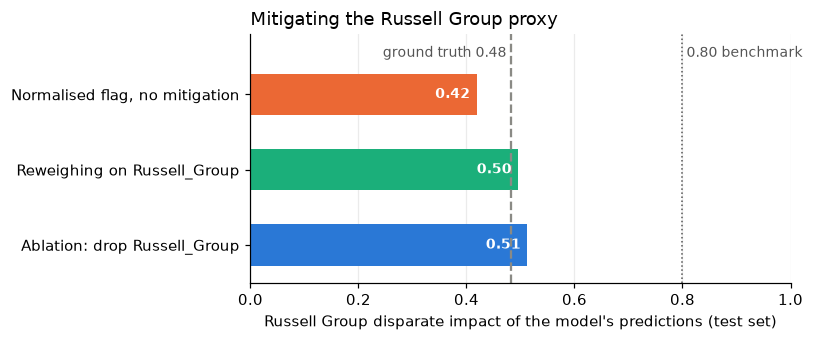

In [17]:
fig, ax = plt.subplots(figsize=(7.5, 3.2))
rows = ["Normalised flag, no mitigation", "Reweighing on Russell_Group", "Ablation: drop Russell_Group"]
vals = [mitigation.loc[r, "RG model DI"] for r in rows]
ax.barh(rows, vals, color=[ORANGE, AQUA, BLUE], height=0.55)
gt = mitigation.loc["Ground truth (labels)", "RG model DI"]
ax.axvline(gt, color=GREY, lw=1.5, ls="--"); ax.text(gt, -0.55, f"ground truth {gt:.2f} ", color="#555", ha="right", va="center", fontsize=9)
ax.axvline(0.8, color="#555", lw=1, ls=":"); ax.text(0.8, -0.55, " 0.80 benchmark", color="#555", ha="left", va="center", fontsize=9)
for i, v in enumerate(vals):
    ax.text(v - 0.012, i, f"{v:.2f}", va="center", ha="right", color="white", fontsize=9, fontweight="bold")
ax.set_xlim(0, 1); ax.set_ylim(2.5, -0.8)
ax.set_xlabel("Russell Group disparate impact of the model's predictions (test set)")
ax.set_title("Mitigating the Russell Group proxy", loc="left")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/followup_mitigation.png", dpi=150, bbox_inches="tight")
plt.show()

Both mitigations remove the **amplification**: the model's Russell Group DI moves from 0.42 back to about the ground-truth level (0.50–0.51 against 0.48). Neither removes the bias that is in the labels themselves, and neither gets near 0.80. Ablation costs 0.2 points of accuracy; Reweighing costs none.

But both make another split worse. **Non-binary vs everyone else falls from 0.851 to 0.734 (ablation) and 0.780 (Reweighing)**, below the benchmark. Without the Russell Group signal, the model leans harder on other features that correlate with gender. Fixing one disparity moved another, the same pattern seen in reverse in `01_lighthr_audit.ipynb`, where gender Reweighing made Russell Group worse.

The practical conclusion is that mitigation has to be checked on every split, not only the one being targeted. The next step would be a joint intervention (for example Reweighing on gender and Russell Group together, or an in-processing method with several fairness constraints), judged on the full table above.